In [366]:
import torch
import math
from torch import nn
import matplotlib.pyplot as plt
import statistics

In [ ]:
# Kør dette for de følgende k-værdier: [2,4,6]
def constructed_function(x, k=6):
    return x**2 + 0.3 * torch.cos(k*math.pi*x)

In [368]:
N, s = 500, 0.01

# Der sættes et tilfældigt seed, så experimentet kan reproduceres
torch.manual_seed(2)

# Dette laver en x-værdi imellem -1 og 1
X = torch.rand(N,1) * 2 - 1
# Vi laver nu en tensor med de tilsvarende y-værdier plus støj
Y = constructed_function(X) + s * torch.randn(N,1)

# Vi laver også et test set. Dette gøres så modellen kan valideres på data den ikke er trænet på
# Hvis en model er overfittet kan det fanges af denne metode
X_test = torch.rand(N,1) * 2 - 1
Y_test = constructed_function(X_test) + s * torch.randn(N,1)

In [369]:
# Der laves en funktion der kan kaldes til at lave en ny model
def make_model(H):
    return nn.Sequential(
        nn.Linear(1,H), nn.ReLU(),
        nn.Linear(H,H), nn.ReLU(),
        nn.Linear(H,1),
    )

In [ ]:
# Denne funktion træner modellen
def train_model():
    learning_rate = 0.01
    n_iters = 20000

    loss = nn.MSELoss()
    # Adam optimizeren er blevet valgt. Dette er et arbitrært valg. 
    optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)

    # Denne løkke opdaterer modellen. Dette kaldes epoker.
    for _ in range(n_iters):

        y_pred = model(X)

        l = loss(Y,y_pred)

        l.backward()

        optimizer.step()
        optimizer.zero_grad()


    return l

# En loss dictionary laves, som skal have antallet af neuroner som key, og loss som value
loss_dict = {}
models = []
# Denne løkke itererer over en liste af 5 forskellige antal neuroner
for H in [2, 4, 8, 16, 32, 64, 128]:
    # Denne liste skal holde losses for hvert forsøg
    test_losses = []
    # Der laves 5 forsøg per antal neuroner til 5 forskellige seeds
    for seednr in range(10):
        torch.manual_seed(seednr)
        model = make_model(H)
        train_model()

        with torch.no_grad():
            test_pred = model(X_test)
        # Gennemsnittet af de 500 prediktioner tages, og appendes på listen test_losses
        test_losses.append(((test_pred - Y_test)**2).mean().item())

    loss_dict[H] = f"{statistics.median(test_losses):.5f}"
    # Tilføjer den sidste af de 5 modeller
    models.append(model)

print(loss_dict)

{2: '0.07896', 4: '0.04620', 8: '0.02889', 16: '0.01851', 32: '0.00041', 64: '0.00020', 128: '0.00021'}


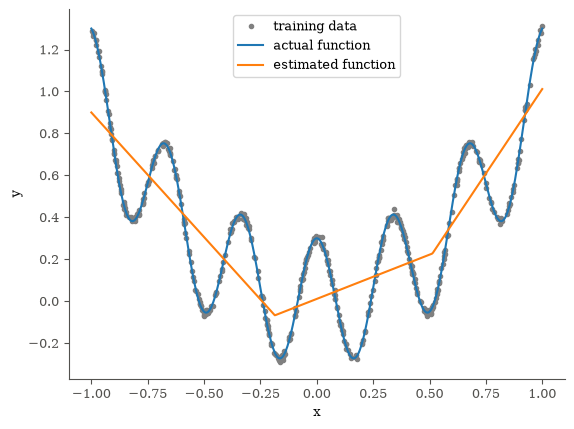

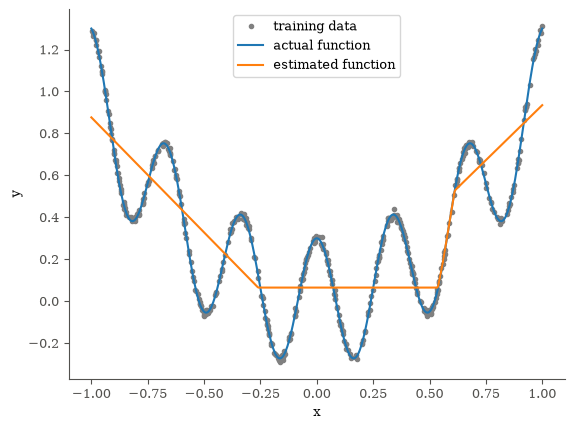

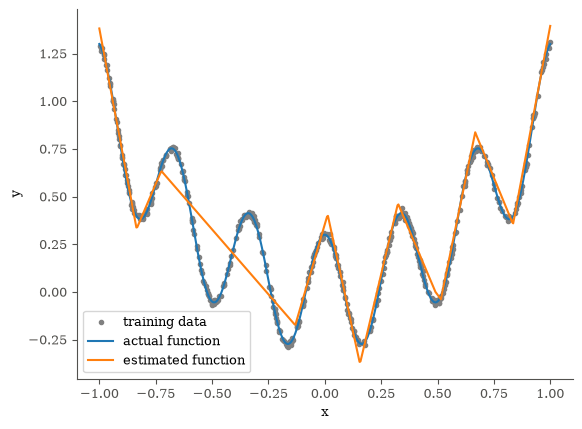

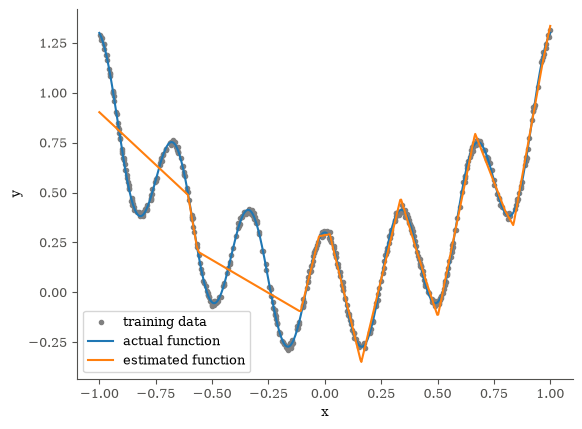

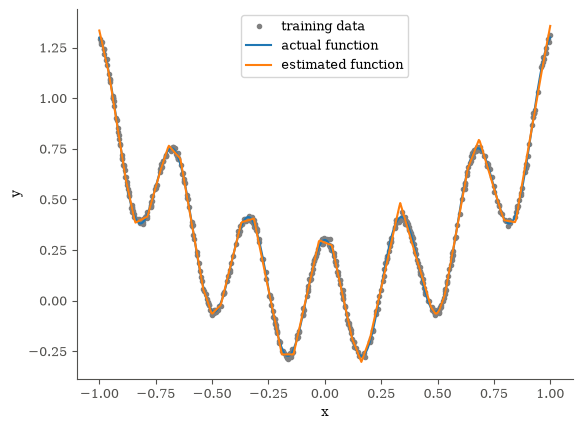

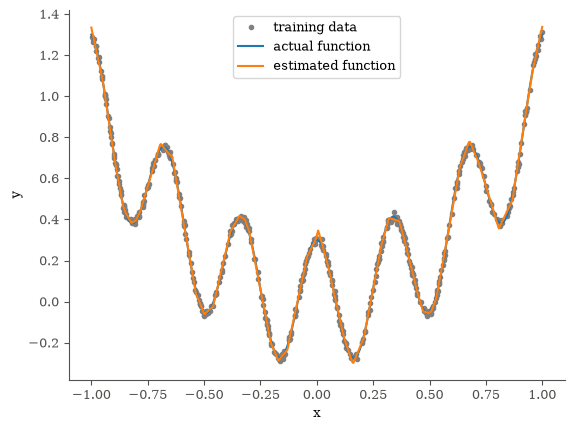

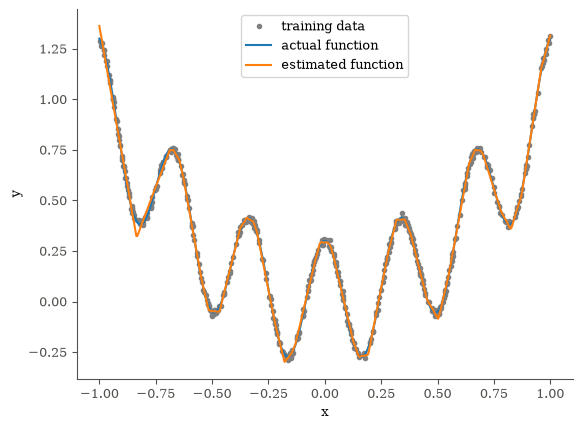

In [ ]:
# Visualisering af modellen op imod den rigtige funktion for k=6
for m in models:

    model = m
    # 500 datapunkter
    xx = torch.linspace(-1, 1, 500).unsqueeze(1)

    with torch.no_grad():
        # Den rigtige funktion
        y_true = constructed_function(xx)          
        # Vores models prediktioner
        y_pred = model(xx)                         

    plt.plot(X, Y, ".", color="gray", label="training data")
    plt.plot(xx, y_true, label="actual function")
    plt.plot(xx, y_pred, label="estimated function")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.show()